## ACCESS-OM3 MC 100km JRA IAF Profiling

This notebook shows how to use [access-profiling](https://access-profiling.readthedocs.io/) to analyse the profiling data of an existing ACCESS-OM3 experiment: the MC 100km JRA IAF configuration, run 66 times with Payu. We go through these steps:

1. Describe the configuration to access-profiling, and create a profiling manager for Payu.
2. Register the experiment, which was run outside access-profiling, with the manager.
3. Parse the profiling logs of every run.
4. Look at how the timings vary from run to run: compare a few runs, keep the best one, and average over all of them. [Run-to-run variability](https://access-profiling.readthedocs.io/latest/user-guide/run-to-run-variability/) explains this in more detail.

The first cell records the versions of the packages used, so that you can tell later which versions produced the results. It also turns on `autoreload`, which reloads a package when its code changes. This is useful if you are working on access-profiling itself.

In [1]:
%load_ext autoreload
%autoreload 2

# Record package versions for future reference
from importlib.metadata import version
for pkg in ("access.config.utils", "access.profiling", "payu", "experiment_generator", "experiment_runner"):
    print(f"{pkg}: {version(pkg)}")

access.config.utils: 0.6.dev10+gca45c2cf0
access.profiling: 0.3.dev15+g5ebd33f96
payu: 1.3.6
experiment_generator: 0.10.2
experiment_runner: 0.3.2


## Setup

In this section we tell access-profiling what we are profiling and where to find it, and create the profiling manager. The cell below defines:

- `work_path`, the working directory of the manager. Every experiment the manager works with must be inside this directory. Here it is the directory of the experiment itself.
- `archive_path`, the directory where `archive_experiments()` saves each experiment as a tarball. A manager created later with the same archive directory finds the archived experiments again, so you can still read their profiling data after the experiment directories are gone.
- `OM3_MC_100KM`, the description of the configuration. It gives the grid of each component: the MOM6 ocean, the CICE6 sea ice, and the data atmosphere and runoff, which all use the same 360 x 324 grid here. `CICEPartitioning` says how CICE6 divides its grid into blocks. access-profiling uses all this to generate parallelisation layouts. The configuration also knows which profiling logs ACCESS-OM3 writes, and where to find them. access-profiling ships a preset for the 25 km configuration, `OM3_MC_25KM`, but not for the 100 km one, so we define it here.
- `OM3_MC_100KM_SOURCE`, where the control configuration comes from: a commit of the access-om3-configs repository. The manager only needs a control to generate new experiments, so it is not used in this notebook. Creating it does not download anything.
- `om3_profiling`, the manager for experiments run with Payu. It registers, runs and archives experiments, and parses, selects and plots their profiling data.

The paths are specific to this study, so adapt them to your own setup.

In [2]:
from pathlib import Path

from access.config.parallel_domain import Domain
from access.profiling import PayuManager, OM3Configuration, CICEPartitioning, GitControlSource
from access.profiling.models.om3 import OM3_CICE6_BLOCKS_PER_RANK_RANGE

work_path = f"/g/data/tm70/ml0072/COMMON/git_repos/MC_100km_jra_iaf+wombatlite-test1/"
archive_path = f"/g/data/tm70/mo1833/ACCESS-OM3/dev-MC_100km_jra_iaf/archive"

# Define the configuration. CICE6 distributes its blocks as set in the control's ice_in, and the block size is
# chosen for each number of cores, so that every rank holds between 5 and 8 blocks.
GLOBAL_GRID = Domain(shape=(360, 324))
OM3_MC_100KM = OM3Configuration(
    name="MC-100km",
    ocean=GLOBAL_GRID,
    sea_ice=CICEPartitioning(
        grid=GLOBAL_GRID.shape,
        distribution_type="cartesian",
        processor_shape="slenderX1",
        blocks_per_rank_range=OM3_CICE6_BLOCKS_PER_RANK_RANGE,
    ),
    atmosphere=GLOBAL_GRID,
    runoff=GLOBAL_GRID,
)

OM3_MC_100KM_SOURCE: GitControlSource = GitControlSource(
    repository="https://github.com/ACCESS-NRI/access-om3-configs.git",
    start_point="7d4166c9e812306edf10a9bfe843739916c3e0e1",
)

# Create profiling manager
om3_profiling = PayuManager(work_dir=Path(work_path), archive_dir=Path(archive_path), application=OM3_MC_100KM, control=OM3_MC_100KM_SOURCE)

# Add experiments

The experiment was not generated by access-profiling, so we register it with `add_experiment_from_directory`, under a name of our choice, `test1`. From now on, this name is how we refer to the experiment, for example in `om3_profiling.data`. The path is the directory the experiment was run from, the one with its `config.yaml` and the `archive` link that Payu creates. A relative path starts from the working directory, so `Path(".")` is the working directory itself. Note that the experiment must be inside the working directory.

The manager assumes that a registered experiment has finished, and marks it as DONE. `parse_profiling_data` checks this again, and skips the experiment, with a warning, if its latest run failed or is still running.

In [3]:
om3_profiling.add_experiment_from_directory("test1", Path("."))

## Parsing and plotting experiment results

`parse_profiling_data` reads the profiling logs of every experiment that has finished. A Payu experiment has one set of logs for each run:

- `payu`, the timings Payu records for the whole job, such as the time spent setting up, running the model and archiving the outputs.
- `MOM6`, the timers (FMS clocks) that MOM6 writes at the end of its standard output.
- `CICE6`, the timers that CICE6 writes in `log/ice.log`.
- `ESMF`, the ESMF profiling summary. ESMF only writes it when the run asks for it, through `ESMF_RUNTIME_PROFILE`, and there is none for this experiment.

A log that is missing or cannot be read is skipped, with an INFO message.

In [4]:
# Parse the data
om3_profiling.parse_profiling_data()

Printing the manager shows what it holds: the application and the control, the two directories, the experiments with their status, and the parsed data. The data is in `om3_profiling.data`, with one xarray `Dataset` for each log of each experiment, for example `om3_profiling.data["test1"]["MOM6"]`. Each dataset has:

- a `region` coordinate, with the names of the timers in the log;
- a `run` coordinate, because `test1` ran several times. Payu numbers the runs after their output directories: 0 for `output000`, 1 for `output001`, and so on;
- one variable for each metric the log provides, with its units. For example, `maximum time` is the time of the PE that spent longest in a region, and `average time` is the mean over the PEs. Payu's timings have a single time per region, stored as `maximum time`.

The variables are keyed by the metric objects of `access.profiling.metrics`, so you select one with, for example, `om3_profiling.data["test1"]["MOM6"][tmax]`. [Log formats](https://access-profiling.readthedocs.io/latest/access/log-formats/) lists the metrics of every log.

Unless the experiment was run with Payu's `repeat` option, each run continues the simulation from the restart files of the previous one. The runs then simulate consecutive periods, and only the first one starts from the initial conditions. A region that is not in the logs of every run, such as a timer of the initialisation, is NaN in the runs that do not have it.

In [5]:
om3_profiling

<PayuManager>
    Application: MC-100km
    Control: 7d4166c9e812306edf10a9bfe843739916c3e0e1
    Working directory: PosixPath('/g/data/tm70/ml0072/COMMON/git_repos/MC_100km_jra_iaf+wombatlite-test1')
    Archive directory: PosixPath('/g/data/tm70/mo1833/ACCESS-OM3/dev-MC_100km_jra_iaf/archive')
    Experiments:
        'test1': ProfilingExperiment(path=PosixPath('/g/data/tm70/ml0072/COMMON/git_repos/MC_100km_jra_iaf+wombatlite-test1'), status=DONE)
    Data:
        'test1':
            'payu':
                <xarray.Dataset> Size: 5kB
                Dimensions:       (run: 66, region: 6)
                Coordinates:
                  * run           (run) int64 528B 0 1 2 3 4 5 6 7 8 ... 58 59 60 61 62 63 64 65
                  * region        (region) <U35 840B 'payu_setup_duration_seconds' ... 'payu_...
                Data variables:
                    maximum time  (run, region) float64 3kB [s] 20.04 3.908e+03 ... 3.925e+03
            'MOM6':
                <xarray.Dataset>

## Run-to-run variability

`test1` ran 66 times, so every dataset above has a `run` dimension, numbered as Payu numbers its outputs. Below we compare a few runs region by region, keep the best run, and compute the average over all the runs. `select_best_run` and `aggregate_runs` both replace `om3_profiling.data`, which is why the runs are compared first.

In [6]:
from access.profiling import RegionGroup
from access.profiling.metrics import tmax

# The regions used in the examples below. om3_profiling.data["test1"]["MOM6"].region.values lists all the regions of a log.
groups = [
    RegionGroup(
        "payu",
        ["payu_model_run_duration_seconds"],
        relabel={"payu_model_run_duration_seconds": "Whole model"},
    ),
    RegionGroup(
        "MOM6",
        ["Total runtime", "Ocean dynamics", "Ocean thermodynamics and tracers"],
        relabel={
            "Total runtime": "MOM6",
            "Ocean dynamics": "MOM6 dynamics",
            "Ocean thermodynamics and tracers": "MOM6 thermodynamics",
        },
    ),
    RegionGroup(
        "CICE6",
        ["Total", "Dynamics", "Column"],
        relabel={"Total": "CICE6", "Dynamics": "CICE6 dynamics", "Column": "CICE6 column"},
    ),
]

### Comparing runs

We pick the fastest, the median and the slowest run, by the time Payu measured for the model run, and plot the regions above side by side. `plot_bar_chart` compares experiments rather than runs, and does not accept data with a `run` dimension, so we take the values of each run ourselves and draw them with `plot_bar_metrics`, the function `plot_bar_chart` uses.

 fastest: run 34, 63.4 min
  median: run 44, 64.9 min
 slowest: run 2, 69.5 min


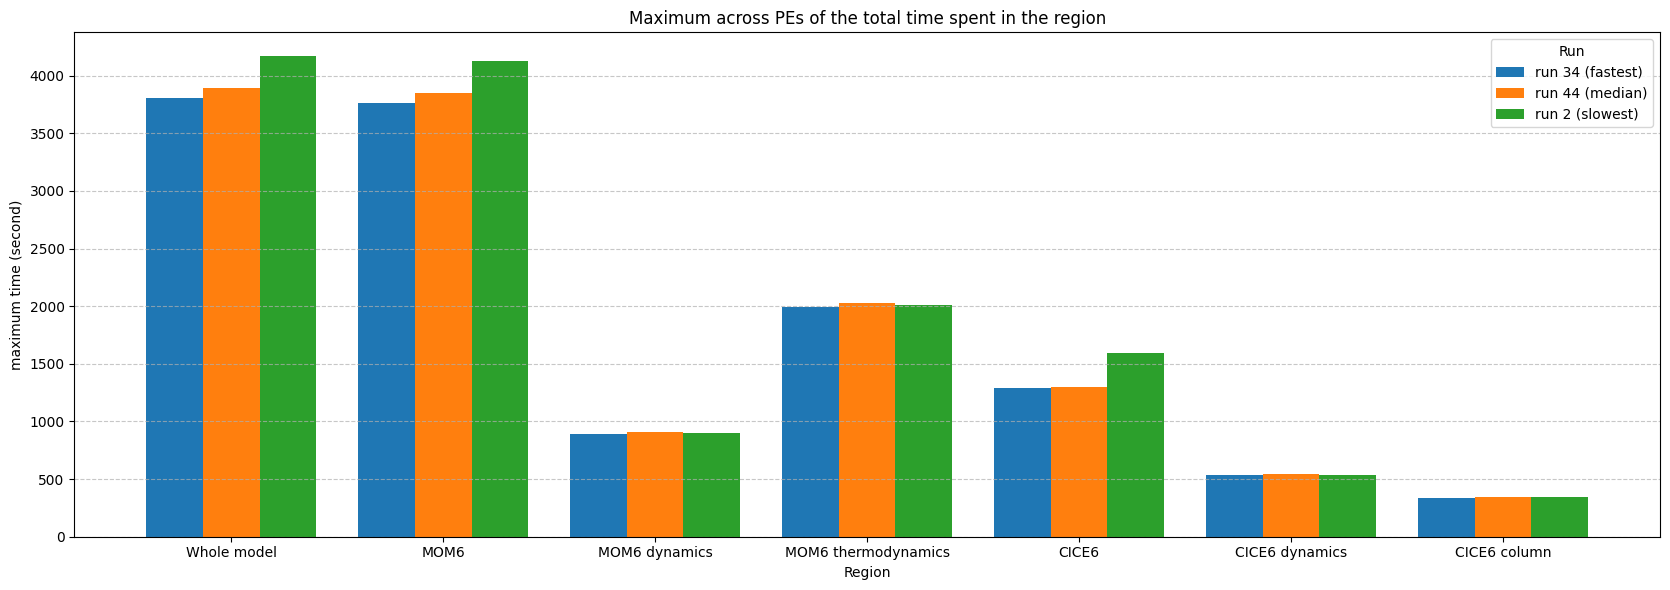

In [7]:
from access.profiling.plotting_utils import plot_bar_metrics

data = om3_profiling.data["test1"]

# Rank the runs by the time Payu measured for the model run, and pick the fastest, the median and the slowest
runtime = data["payu"][tmax].sel(region="payu_model_run_duration_seconds").pint.to("minute").pint.dequantify()
ranked = runtime.sortby(runtime).run.values
runs = {"fastest": ranked[0], "median": ranked[len(ranked) // 2], "slowest": ranked[-1]}
for label, run in runs.items():
    print(f"{label:>8}: run {run}, {float(runtime.sel(run=run)):.1f} min")

# One bar per run in each region
region_labels = [group.label(region) for group in groups for region in group.regions]
bar_data = {
    f"run {run} ({label})": [
        float(data[group.log][tmax].sel(run=run, region=region).pint.dequantify())
        for group in groups
        for region in group.regions
    ]
    for label, run in runs.items()
}
fig = plot_bar_metrics(bar_data, region_labels, tmax, show=False)
fig.axes[0].get_legend().set_title("Run")  # plot_bar_metrics calls it "Experiment"

### Selecting the best run

`select_best_run` keeps the run in which a region we choose was fastest, here the model run as Payu timed it. The same run is kept in every log, so the result is a run that really happened. The `run` dimension is gone afterwards, so the data can now be passed to the manager's plots and to `select_best_experiments`.

In [8]:
om3_profiling.select_best_run("payu", "payu_model_run_duration_seconds", tmax)

best = om3_profiling.data["test1"]["payu"][tmax].sel(region="payu_model_run_duration_seconds")
print(f"Model run time of the best run: {float(best.pint.to('minute').pint.dequantify()):.1f} min")
om3_profiling.data["test1"]["payu"]

Model run time of the best run: 63.4 min


Magnitude,[11.336312079802155 3802.389062174596 3812.876369310543 2.3515219688415527 4.127109012566507 3841.554682]
Units,second


### Average time per run

`aggregate_runs` computes the minimum, the mean or the median over the runs. Each region and metric is reduced separately, so unlike `select_best_run`, the values of different regions may come from different runs. `select_best_run` replaced the data above, so we first parse the logs again to get all the runs back.

In [9]:
om3_profiling.parse_profiling_data()
om3_profiling.aggregate_runs(how="mean")

for group in groups:
    for region in group.regions:
        mean = om3_profiling.data["test1"][group.log][tmax].sel(region=region)
        print(f"{group.label(region):>20}: {float(mean.pint.dequantify()):8.1f} s")

         Whole model:   3897.6 s
                MOM6:   3856.8 s
       MOM6 dynamics:    907.9 s
 MOM6 thermodynamics:   2013.0 s
               CICE6:   1307.1 s
      CICE6 dynamics:    544.2 s
        CICE6 column:    343.1 s
